# Molecular docking -- Lavandula_angustifolia vs PPAR-alpha (1K7L)

Protein: Human PPAR-alpha ligand-binding domain, PDB 1K7L, native agonist GW409544 (ligand code 544). Only chain A (the receptor) is used for docking -- the crystal also contains a short co-activator peptide (chain B) bound to the receptor surface, a real part of the active conformation but not the small-molecule ligand pocket, excluded here as is standard practice for nuclear-receptor docking. Compounds: Linalyl_acetate, Linalool, Hexyl_butyrate, Lavandulyl_acetate (Saifi et al. 2026, Tlemcen).

## Content of this notebook

1. Feching system and cleanup
2. Protein and ligand sanitization
3. System Visualization 
4. Docking with AutoDock Vina
    - Receptor preparation
    - Ligand preparation
    - Docking box definition
    - Docking
    - PDBQT results file conversion to SDF
    - 3D visualization of docking results
    - 2D interaction table and map
5. Docking with Smina
    - Receptor preparation
    - Ligand preparation
    - Docking box definition
    - Docking
    - 3D visualization of docking results
    - 2D interaction table and map
6. Docking with LeDock
    - Receptor preparation
    - Ligand preparation
    - Docking box definition
    - Docking
    - DOK results file conversion to SDF
    - 3D visualization of docking results
    - 2D interaction table and map

In [1]:
from pymol import cmd
import py3Dmol

from vina import Vina

from openbabel import pybel

from rdkit import Chem
from rdkit.Chem import AllChem, Draw

from meeko import MoleculePreparation

import MDAnalysis as mda
from MDAnalysis.coordinates import PDB

import prolif as plf
from prolif.plotting.network import LigNetwork


import sys, os
sys.path.insert(1, "/home/ali/medical plants/docking/Jupyter_Dock-main/utilities/")
from utils import fix_protein, getbox, generate_ledock_file, pdbqt_to_sdf, dok_to_sdf


import warnings
warnings.filterwarnings("ignore")
%config Completer.use_jedi = False

/home/ali/Downloads/or/envs/jupdock_clean/lib/python3.10/site-packages/MDAnalysis/topology/tables.py:52: DeprecationWarning: Deprecated in version 2.8.0
MDAnalysis.topology.tables has been moved to MDAnalysis.guesser.tables. This import point will be removed in MDAnalysis version 3.0.0
  warnings.warn(wmsg, category=DeprecationWarning)


It's a good idea to run the test protocols before attempting custom projects. Later, the user can specify the location of his/her project and save all of the files separately.

In [2]:
os.chdir('/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/')


## 1. Feching system and cleanup

Implementing Pymol is a simple way to download PDB structures. The user can launch this or any other Jupyter Dock's protocol by providing his or her own files.

In [3]:
cmd.fetch(code='1K7L',type='pdb1')

# 1K7L contains the PPAR-alpha LBD (chain A) PLUS a short co-activator
# peptide (chain B) bound to the receptor surface (part of the real active
# conformation, but not the small-molecule ligand pocket). Keep chain A
# only for the docking receptor.
cmd.select(name='Prot', selection='polymer.protein and chain A')
cmd.save(filename='1K7L_clean.pdb', format='pdb', selection='Prot', state=1)

# Native ligand: GW409544, PDB ligand code 544, chain A.
cmd.select(name='NativeLig', selection='resn 544 and chain A')
_natlig_model = cmd.get_model('NativeLig', state=1)
print("Native ligand (GW409544) atom count:", len(_natlig_model.atom))
cmd.save(filename='1K7L_native_lig.mol2', format='mol2', selection='NativeLig', state=1)
cmd.delete('all')


Native ligand (GW409544) atom count: 38


## 2. Protein and ligand sanitization

### 2.1. Protein Sanitization

#### Method 1: LePro

The Lephar molecular docking suite includes a very powerful tool for automatically preparing proteins for molecular docking. As a result, for these protocols, it will be the preferred tool for protein preparation. The protein prepared by LePro can be used in AutoDock VIna and LeDock.

In [4]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" # Launch this cell to see parameters


************************************************************
*      LePro                                               *
*            Add hydrogen atoms to a protein &             *
*            write the input file for LeDock               *
*      Copyright (C) 2013-21 Hongtao Zhao, PhD             *
*      Email: htzhaovv@gmail.com                           *
************************************************************
----------Usage:                                                                       
          lepro [PDB file] [-rot || -metal || -p]                                        
          -rot  [[chain] resid] align principal axes of the binding site with Cartesian
          -metal keep ZN/MN/CA/MG                                                      
          -metal -p redistribute metal charge to protein                               



In [5]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" {'1K7L_clean.pdb'}

os.rename('pro.pdb','1K7L_clean_H.pdb')


#### Method 2: fix_protein (PDBFixer)

For proteins with missing amino acids or residues, or to ensure a more thorough sanitization of protein Jupyter Dock includes the _fix_protein()_ function, which employs PDBFixer to correct a wide range of common errors in protein pdb files. Furthermore, PDBFixer enables the assignment of pH-dependent protonation states to proteins.


>**Warning 1:**  It is possible to encounter problems with protein fixing when using **_fix_protein()_** and AutoDock Tools' **_prepare_receptor_** or when running LeDock. To resolve the issue, it is best to set the parameter _-A hydrogens_ in _prepare receptor_.


>**Hint:** PDBFixer is a great solution for many systems because it can solve serious problems in PDB files. As a result, PDBFixer renumbers the residues beginning with 1 regardless of the numbering on the original PDB file. To address this issue, the **_fix_protein()_** function includes a protocol for atomically renumbering the residues in accordance with the original PDB file.


**_fix_protein ( params )_**

Params:
      
  - **filename**: _str or path-like_ ; input file containing protein struture to be modified, file extrension must be pdb

  - **addHs_pH**: _float_ ; Add hydrogens at user defined pH

  - **try_renumberResidues**: _bool_ ; By default PDBFixer renumarets residues starting in 1, this option tries to recover originar residues numbering
    
  - **output**: _str or path-like_ ; output filename, extension must be pdb

```
fix_protein(filename='1K7L_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='1K7L_clean_H.pdb')
```

## 4. Docking with AutoDock Vina

AutoDock Vina (Vina) is one of the docking engines in the AutoDock Suite, together with AutoDock4 (AD4), AutoDockGPU, AutoDockFR, and AutoDock-CrankPep, and arguably among the most widely used and successful docking engines. The reasons for this success are mostly due to its ease of use and its speed (up to 100x faster than AD4), when compared to the other docking engines in the suite and elsewhere, as well as being open source.

### 4.1. Protein preparation

After sanitization, the protein docking preparation includes converting it to the PDBQT file format, which stores the atomic coordinates, partial charges, and AutoDock atom types for both the receptor and the ligand. 

>**Hint:** Despite the fact that the PDBQT format includes changes (Q) and atom types (T) for molecular docking. The charges are not required for Autodock Vina, which computes electrostatic interactions using its own force field. Although, when using AutoDock instead of AutoDock Vina, the Q term is required. More information can be found here:https://autodock-vina.readthedocs.io/en/latest/introduction.html

#### Method 1: AutoDock Tools prepare_receptor

The AutoDock Tools are the best way to prepare the receptor for AutoDock Vina. Nonetheless, AutoDock Tools is a comprehensive suite of programs and scripts that are difficult to manage. Jupyter Dock execute the **_prepare receptor_** and **_prepare_ligand_** functions on their own. As a result, obtaining proper PDBQT files for AutoDock Vina has never been easier.

>**Warning:** There is currently only one method for preparing a PDBQT file for a receptor. It is expected that new methods apart from AutoDock Tools executables will be included in the near future into Jupyter Dock.

In [6]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" #Lauch this cell to see parameters


prepare_receptor4: receptor filename must be specified.
Usage: prepare_receptor4.py -r filename

    Description of command...
         -r   receptor_filename 
        supported file types include pdb,mol2,pdbq,pdbqs,pdbqt, possibly pqr,cif
    Optional parameters:
        [-v]  verbose output (default is minimal output)
        [-o pdbqt_filename]  (default is 'molecule_name.pdbqt')
        [-A]  type(s) of repairs to make: 
             'bonds_hydrogens': build bonds and add hydrogens 
             'bonds': build a single bond from each atom with no bonds to its closest neighbor
             'hydrogens': add hydrogens
             'checkhydrogens': add hydrogens only if there are none already
             'None': do not make any repairs 
             (default is 'None')
        [-C]  preserve all input charges ie do not add new charges 
             (default is addition of gasteiger charges)
        [-p]  preserve input charges on specific atom types, eg -p Zn -p Fe
        [-U]  cle

In [7]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" -v -r {'1K7L_clean_H.pdb'} -o {'1K7L_clean_H.pdbqt'}

# If this raises "UnboundLocalError: local variable 'bonds' referenced before
# assignment", use this fallback:
# import subprocess
# r = subprocess.run(["obabel", "1K7L_clean_H.pdb", "-O", "1K7L_clean_H.pdbqt", "-xr"],
#                     capture_output=True, text=True)
# print(r.stdout, r.stderr)


set verbose to  True
set receptor_filename to  1K7L_clean_H.pdb
set outputfilename to  1K7L_clean_H.pdbqt
read  1K7L_clean_H.pdb
setting up RPO with mode= automatic and outputfilename=  1K7L_clean_H.pdbqt
charges_to_add= gasteiger
delete_single_nonstd_residues= None
adding gasteiger charges to peptide


In [8]:
fix_protein(filename='1K7L_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='1K7L_clean_H_fix.pdb')

## 7. Screening PHYTO compounds (Lavandula_angustifolia) against PPAR-alpha (1K7L)

Reuses the receptor (`1K7L_clean_H.pdb`/`.pdbqt`, chain A only) and the
docking box (native ligand GW409544, chain A, `state=1` -- Section 1)
prepared above. Each compound docked in its own cell with its own
uniquely-named variables, seed pinned at 42. Source: Saifi et al. 2026
(Tlemcen).

In [9]:
import os
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolDescriptors
from openbabel import openbabel as ob
from vina import Vina
import pandas as pd
import matplotlib.pyplot as plt

DOCKING_DIR = "/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/"
FIGURES_DIR = os.path.join(DOCKING_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.chdir(DOCKING_DIR)

RECEPTOR_PDB   = os.path.join(DOCKING_DIR, "1K7L_clean_H.pdb")
RECEPTOR_PDBQT = os.path.join(DOCKING_DIR, "1K7L_clean_H.pdbqt")
NATIVE_LIG     = os.path.join(DOCKING_DIR, "1K7L_native_lig.mol2")

assert os.path.exists(RECEPTOR_PDBQT), "Run the receptor prep cells above first."
assert os.path.exists(NATIVE_LIG), "Run the native ligand extraction cell above first."

VINA_SEED = 42  # pinned for reproducibility

def prepare_ligand_from_smiles(name, smiles, n_confs=20):
    """SMILES -> multiple 3D conformers (ETKDGv3) -> MMFF94 minimize each ->
    keep lowest-energy conformer -> PDB -> PDBQT (AutoDockTools prepare_ligand,
    with OpenBabel fallback)."""
    import subprocess
    m = Chem.MolFromSmiles(smiles)
    m = Chem.AddHs(m)

    params = AllChem.ETKDGv3()
    params.randomSeed = 42
    conf_ids = AllChem.EmbedMultipleConfs(m, numConfs=n_confs, params=params)

    energies = []
    for cid in conf_ids:
        ff = AllChem.MMFFGetMoleculeForceField(m, AllChem.MMFFGetMoleculeProperties(m), confId=cid)
        if ff is None:
            continue
        ff.Minimize(maxIts=2000)
        energies.append((ff.CalcEnergy(), cid))
    if not energies:
        for cid in conf_ids:
            ff = AllChem.UFFGetMoleculeForceField(m, confId=cid)
            ff.Minimize(maxIts=2000)
            energies.append((ff.CalcEnergy(), cid))

    best_energy, best_cid = min(energies, key=lambda x: x[0])
    print(f"  {name}: {len(conf_ids)} conformers generated, "
          f"lowest energy = {best_energy:.2f} kcal/mol (conf {best_cid})")

    pdb_path   = os.path.join(DOCKING_DIR, f'_lig_{name}.pdb')
    pdbqt_path = os.path.join(DOCKING_DIR, f'_lig_{name}.pdbqt')
    Chem.MolToPDBFile(m, pdb_path, confId=best_cid)

    PREP_LIG_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand"
    result = subprocess.run([PREP_LIG_BIN, "-v", "-l", pdb_path, "-o", pdbqt_path],
                             capture_output=True, text=True)
    if not os.path.exists(pdbqt_path) or os.path.getsize(pdbqt_path) == 0:
        obConv = ob.OBConversion()
        obConv.SetInAndOutFormats('pdb', 'pdbqt')
        obmol = ob.OBMol()
        obConv.ReadFile(obmol, pdb_path)
        obConv.WriteFile(obmol, pdbqt_path)

    return pdbqt_path


### 7.1. Recompute the docking box (native ligand GW409544, `state=1`)

In [10]:
cmd.load(filename=RECEPTOR_PDB, format='pdb', object='prot', state=1)
cmd.load(filename=NATIVE_LIG, format='mol2', object='natlig', state=1)

center, size = getbox(selection='natlig', extending=5.0, software='vina')
cmd.delete('all')

print(center, '\n', size)


{'center_x': -16.445500373840332, 'center_y': -15.031999588012695, 'center_z': -3.883500039577484} 
 {'size_x': 20.571001052856445, 'size_y': 18.091999053955078, 'size_z': 20.402999997138977}


### 7.2. Dock **Linalyl_acetate** against PPAR-alpha (1K7L)

In [11]:
# ---- Linalyl_acetate (Lavandula_angustifolia, Saifi et al. 2026) ----
smiles_Linalyl_acetate = "CC(=CCCC(C)(C=C)OC(C)=O)C"
lig_pdbqt_Linalyl_acetate = prepare_ligand_from_smiles("Linalyl_acetate", smiles_Linalyl_acetate)

v_Linalyl_acetate = Vina(sf_name='vina', seed=VINA_SEED)
v_Linalyl_acetate.set_receptor(RECEPTOR_PDBQT)
v_Linalyl_acetate.set_ligand_from_file(lig_pdbqt_Linalyl_acetate)
v_Linalyl_acetate.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Linalyl_acetate.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Linalyl_acetate = os.path.join(DOCKING_DIR, "Linalyl_acetate_1K7L_vina_out.pdbqt")
v_Linalyl_acetate.write_poses(vina_out_pdbqt_Linalyl_acetate, n_poses=10, overwrite=True)

energies_Linalyl_acetate = v_Linalyl_acetate.energies(n_poses=10)
best_score_Linalyl_acetate = round(float(energies_Linalyl_acetate[0][0]), 3)

print("=== Linalyl_acetate ===")
print(f"Best Vina score: {best_score_Linalyl_acetate} kcal/mol")
for i, e in enumerate(energies_Linalyl_acetate):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Linalyl_acetate = vina_out_pdbqt_Linalyl_acetate.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Linalyl_acetate, output=vina_out_sdf_Linalyl_acetate)


  Linalyl_acetate: 20 conformers generated, lowest energy = 12.96 kcal/mol (conf 3)
Computing Vina grid ... done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
=== Linalyl_acetate ===
Best Vina score: -6.277 kcal/mol
  Pose 1: -6.277
  Pose 2: -6.222
  Pose 3: -5.944
  Pose 4: -5.599
  Pose 5: -5.582
  Pose 6: -5.572
  Pose 7: -5.407
  Pose 8: -5.296
  Pose 9: -5.279
  Pose 10: -5.228


### 7.3. Dock **Linalool** against PPAR-alpha (1K7L)

In [12]:
# ---- Linalool (Lavandula_angustifolia, Saifi et al. 2026) ----
smiles_Linalool = "CC(C)=CCCC(C)(O)C=C"
lig_pdbqt_Linalool = prepare_ligand_from_smiles("Linalool", smiles_Linalool)

v_Linalool = Vina(sf_name='vina', seed=VINA_SEED)
v_Linalool.set_receptor(RECEPTOR_PDBQT)
v_Linalool.set_ligand_from_file(lig_pdbqt_Linalool)
v_Linalool.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Linalool.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Linalool = os.path.join(DOCKING_DIR, "Linalool_1K7L_vina_out.pdbqt")
v_Linalool.write_poses(vina_out_pdbqt_Linalool, n_poses=10, overwrite=True)

energies_Linalool = v_Linalool.energies(n_poses=10)
best_score_Linalool = round(float(energies_Linalool[0][0]), 3)

print("=== Linalool ===")
print(f"Best Vina score: {best_score_Linalool} kcal/mol")
for i, e in enumerate(energies_Linalool):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Linalool = vina_out_pdbqt_Linalool.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Linalool, output=vina_out_sdf_Linalool)


  Linalool: 20 conformers generated, lowest energy = 16.17 kcal/mol (conf 4)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -6.277          0          0
   2       -6.222      1.558      3.031
   3       -5.944      1.702       2.61
   4       -5.599      1.857      4.461
   5       -5.582      1.606      2.092
   6       -5.572      12.38      14.39
   7       -5.407      2.841      4.656
   8       -5.296      11.29      13.64
   9       -5.279      1.614      4.668
  10       -5.228      2.442      5.827
Computing Vina grid ... done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
=== Linalool ===
Best Vina score: -6.097 kcal/mol
  Pose 1: -6.097
  Pose 2: -6.082
  Pose 3: -5.433
  Pose 4: -5.419
  Pose 5: -5.410
  Pose 6: -5.351
  Pose 7: -5.066


### 7.4. Dock **Hexyl_butyrate** against PPAR-alpha (1K7L)

In [13]:
# ---- Hexyl_butyrate (Lavandula_angustifolia, Saifi et al. 2026) ----
smiles_Hexyl_butyrate = "CCCCCCOC(=O)CCC"
lig_pdbqt_Hexyl_butyrate = prepare_ligand_from_smiles("Hexyl_butyrate", smiles_Hexyl_butyrate)

v_Hexyl_butyrate = Vina(sf_name='vina', seed=VINA_SEED)
v_Hexyl_butyrate.set_receptor(RECEPTOR_PDBQT)
v_Hexyl_butyrate.set_ligand_from_file(lig_pdbqt_Hexyl_butyrate)
v_Hexyl_butyrate.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Hexyl_butyrate.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Hexyl_butyrate = os.path.join(DOCKING_DIR, "Hexyl_butyrate_1K7L_vina_out.pdbqt")
v_Hexyl_butyrate.write_poses(vina_out_pdbqt_Hexyl_butyrate, n_poses=10, overwrite=True)

energies_Hexyl_butyrate = v_Hexyl_butyrate.energies(n_poses=10)
best_score_Hexyl_butyrate = round(float(energies_Hexyl_butyrate[0][0]), 3)

print("=== Hexyl_butyrate ===")
print(f"Best Vina score: {best_score_Hexyl_butyrate} kcal/mol")
for i, e in enumerate(energies_Hexyl_butyrate):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Hexyl_butyrate = vina_out_pdbqt_Hexyl_butyrate.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Hexyl_butyrate, output=vina_out_sdf_Hexyl_butyrate)


  Hexyl_butyrate: 20 conformers generated, lowest energy = -13.61 kcal/mol (conf 1)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -6.097          0          0
   2       -6.082      1.709      2.486
   3       -5.433      3.517      4.992
   4       -5.419      1.396      2.362
   5        -5.41      1.677      5.662
   6       -5.351      1.675      5.663
   7       -5.066      3.191      5.307
   8       -5.031      4.037      5.985
   9       -5.004      4.348      5.247
  10       -4.857      13.52      15.11
Computing Vina grid ... done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
=== Hexyl_butyrate ===
Best Vina score: -5.559 kcal/mol
  Pose 1: -5.559
  Pose 2: -5.539
  Pose 3: -5.432
  Pose 4: -5.028
  Pose 5: -5.003
  Pose 6: -4.863
  Po

### 7.5. Dock **Lavandulyl_acetate** against PPAR-alpha (1K7L)

In [14]:
# ---- Lavandulyl_acetate (Lavandula_angustifolia, Saifi et al. 2026) ----
smiles_Lavandulyl_acetate = "CC(=CCC(C)(C=C)COC(C)=O)C"
lig_pdbqt_Lavandulyl_acetate = prepare_ligand_from_smiles("Lavandulyl_acetate", smiles_Lavandulyl_acetate)

v_Lavandulyl_acetate = Vina(sf_name='vina', seed=VINA_SEED)
v_Lavandulyl_acetate.set_receptor(RECEPTOR_PDBQT)
v_Lavandulyl_acetate.set_ligand_from_file(lig_pdbqt_Lavandulyl_acetate)
v_Lavandulyl_acetate.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Lavandulyl_acetate.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Lavandulyl_acetate = os.path.join(DOCKING_DIR, "Lavandulyl_acetate_1K7L_vina_out.pdbqt")
v_Lavandulyl_acetate.write_poses(vina_out_pdbqt_Lavandulyl_acetate, n_poses=10, overwrite=True)

energies_Lavandulyl_acetate = v_Lavandulyl_acetate.energies(n_poses=10)
best_score_Lavandulyl_acetate = round(float(energies_Lavandulyl_acetate[0][0]), 3)

print("=== Lavandulyl_acetate ===")
print(f"Best Vina score: {best_score_Lavandulyl_acetate} kcal/mol")
for i, e in enumerate(energies_Lavandulyl_acetate):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Lavandulyl_acetate = vina_out_pdbqt_Lavandulyl_acetate.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Lavandulyl_acetate, output=vina_out_sdf_Lavandulyl_acetate)


  Lavandulyl_acetate: 20 conformers generated, lowest energy = 32.95 kcal/mol (conf 5)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -5.559          0          0
   2       -5.539      1.783      6.404
   3       -5.432      1.299      1.564
   4       -5.028      2.351      6.267
   5       -5.003      2.896      5.518
   6       -4.863      2.536      4.937
   7       -4.854      2.252       3.29
   8       -4.837      2.417      4.685
   9       -4.815      3.301      5.023
  10        -4.69       3.63      5.172
Computing Vina grid ... done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
=== Lavandulyl_acetate ===
Best Vina score: -6.328 kcal/mol
  Pose 1: -6.328
  Pose 2: -6.086
  Pose 3: -6.054
  Pose 4: -6.002
  Pose 5: -5.856
  Pose 6: -5.7

### 7.6. Total docking results table -- Lavandula_angustifolia vs PPAR-alpha (1K7L)

In [15]:
docking_rows_angustifolia_PPAR = [
    {"Compound": "Linalyl_acetate",    "Target": "PPAR-alpha (1K7L)", "Best_Vina_Score_kcal_mol": best_score_Linalyl_acetate},
    {"Compound": "Linalool",           "Target": "PPAR-alpha (1K7L)", "Best_Vina_Score_kcal_mol": best_score_Linalool},
    {"Compound": "Hexyl_butyrate",     "Target": "PPAR-alpha (1K7L)", "Best_Vina_Score_kcal_mol": best_score_Hexyl_butyrate},
    {"Compound": "Lavandulyl_acetate", "Target": "PPAR-alpha (1K7L)", "Best_Vina_Score_kcal_mol": best_score_Lavandulyl_acetate},
]

docking_df_angustifolia_PPAR = pd.DataFrame(docking_rows_angustifolia_PPAR).sort_values("Best_Vina_Score_kcal_mol").reset_index(drop=True)
docking_df_angustifolia_PPAR.to_csv(os.path.join(DOCKING_DIR, "lavandula_angustifolia_vs_PPARalpha_vina.csv"), index=False)
docking_df_angustifolia_PPAR


,Compound,Target,Best_Vina_Score_kcal_mol
0,Lavandulyl_acetate,PPAR-alpha (1K7L),-6.328
1,Linalyl_acetate,PPAR-alpha (1K7L),-6.277
2,Linalool,PPAR-alpha (1K7L),-6.097
3,Hexyl_butyrate,PPAR-alpha (1K7L),-5.559


### 7.7. Figure -- docking score comparison, Lavandula_angustifolia vs PPAR-alpha

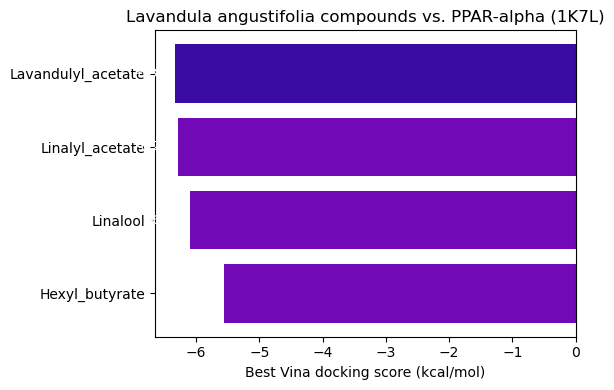

Saved figure: /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/figures/lavandula_angustifolia_vs_PPARalpha_scores.png


In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
colors = ['#3a0ca3' if s == docking_df_angustifolia_PPAR['Best_Vina_Score_kcal_mol'].min() else '#7209b7'
          for s in docking_df_angustifolia_PPAR['Best_Vina_Score_kcal_mol']]
ax.barh(docking_df_angustifolia_PPAR['Compound'], docking_df_angustifolia_PPAR['Best_Vina_Score_kcal_mol'], color=colors)
ax.set_xlabel('Best Vina docking score (kcal/mol)')
ax.set_title('Lavandula angustifolia compounds vs. PPAR-alpha (1K7L)')
ax.invert_yaxis()
for i, v in enumerate(docking_df_angustifolia_PPAR['Best_Vina_Score_kcal_mol']):
    ax.text(v - 0.15, i, f"{v:.2f}", va='center', ha='right', fontsize=9, color='white')
plt.tight_layout()

fig_path_angustifolia_PPAR = os.path.join(FIGURES_DIR, 'lavandula_angustifolia_vs_PPARalpha_scores.png')
plt.savefig(fig_path_angustifolia_PPAR, dpi=300, bbox_inches='tight')
plt.show()
print("Saved figure:", fig_path_angustifolia_PPAR)


### 7.8. ProLif interaction fingerprints -- Lavandula_angustifolia vs PPAR-alpha (each compound, own cell)

`n_jobs=1` avoids a multiprocessing/pickling crash in this environment;
`to_dataframe()` takes no arguments in ProLif 2.2.1.

In [17]:
prot_fp = mda.Universe("1K7L_clean_H_fix.pdb")  # fix_protein() output
prot_fp = plf.Molecule.from_mda(prot_fp)


[RDKit] ERROR:[10:56:45] Explicit valence for atom # 2822 C, 5, is greater than permitted


AtomValenceException: Explicit valence for atom # 2822 C, 5, is greater than permitted

In [ ]:
# ---- ProLif: Linalyl_acetate ----
lig_suppl_Linalyl_acetate = list(plf.sdf_supplier(vina_out_sdf_Linalyl_acetate))
fp_Linalyl_acetate = plf.Fingerprint()
fp_Linalyl_acetate.run_from_iterable(lig_suppl_Linalyl_acetate, prot_fp, n_jobs=1)
results_df_Linalyl_acetate = fp_Linalyl_acetate.to_dataframe()

print("=== Linalyl_acetate ===")
display(results_df_Linalyl_acetate)

net_Linalyl_acetate = fp_Linalyl_acetate.plot_lignetwork(lig_suppl_Linalyl_acetate[0], kind="frame", frame=0, rotation=270)
net_png_Linalyl_acetate = os.path.join(FIGURES_DIR, "Linalyl_acetate_1K7L_2Dnetwork.png")
net_Linalyl_acetate.save_png(net_png_Linalyl_acetate)
print("Saved network figure:", net_png_Linalyl_acetate)


In [ ]:
# ---- ProLif: Linalool ----
lig_suppl_Linalool = list(plf.sdf_supplier(vina_out_sdf_Linalool))
fp_Linalool = plf.Fingerprint()
fp_Linalool.run_from_iterable(lig_suppl_Linalool, prot_fp, n_jobs=1)
results_df_Linalool = fp_Linalool.to_dataframe()

print("=== Linalool ===")
display(results_df_Linalool)

net_Linalool = fp_Linalool.plot_lignetwork(lig_suppl_Linalool[0], kind="frame", frame=0, rotation=270)
net_png_Linalool = os.path.join(FIGURES_DIR, "Linalool_1K7L_2Dnetwork.png")
net_Linalool.save_png(net_png_Linalool)
print("Saved network figure:", net_png_Linalool)


In [ ]:
# ---- ProLif: Hexyl_butyrate ----
lig_suppl_Hexyl_butyrate = list(plf.sdf_supplier(vina_out_sdf_Hexyl_butyrate))
fp_Hexyl_butyrate = plf.Fingerprint()
fp_Hexyl_butyrate.run_from_iterable(lig_suppl_Hexyl_butyrate, prot_fp, n_jobs=1)
results_df_Hexyl_butyrate = fp_Hexyl_butyrate.to_dataframe()

print("=== Hexyl_butyrate ===")
display(results_df_Hexyl_butyrate)

net_Hexyl_butyrate = fp_Hexyl_butyrate.plot_lignetwork(lig_suppl_Hexyl_butyrate[0], kind="frame", frame=0, rotation=270)
net_png_Hexyl_butyrate = os.path.join(FIGURES_DIR, "Hexyl_butyrate_1K7L_2Dnetwork.png")
net_Hexyl_butyrate.save_png(net_png_Hexyl_butyrate)
print("Saved network figure:", net_png_Hexyl_butyrate)


In [ ]:
# ---- ProLif: Lavandulyl_acetate ----
lig_suppl_Lavandulyl_acetate = list(plf.sdf_supplier(vina_out_sdf_Lavandulyl_acetate))
fp_Lavandulyl_acetate = plf.Fingerprint()
fp_Lavandulyl_acetate.run_from_iterable(lig_suppl_Lavandulyl_acetate, prot_fp, n_jobs=1)
results_df_Lavandulyl_acetate = fp_Lavandulyl_acetate.to_dataframe()

print("=== Lavandulyl_acetate ===")
display(results_df_Lavandulyl_acetate)

net_Lavandulyl_acetate = fp_Lavandulyl_acetate.plot_lignetwork(lig_suppl_Lavandulyl_acetate[0], kind="frame", frame=0, rotation=270)
net_png_Lavandulyl_acetate = os.path.join(FIGURES_DIR, "Lavandulyl_acetate_1K7L_2Dnetwork.png")
net_Lavandulyl_acetate.save_png(net_png_Lavandulyl_acetate)
print("Saved network figure:", net_png_Lavandulyl_acetate)


### 7.9. Figure -- best-scoring compound vs. the real native ligand (GW409544)

In [ ]:
best_row_angustifolia_PPAR = docking_df_angustifolia_PPAR.iloc[0]
best_compound_angustifolia_PPAR = best_row_angustifolia_PPAR['Compound']
print("Best-scoring compound:", best_compound_angustifolia_PPAR, "|", best_row_angustifolia_PPAR['Best_Vina_Score_kcal_mol'], "kcal/mol")

best_sdf_angustifolia_PPAR = {
    "Linalyl_acetate": vina_out_sdf_Linalyl_acetate,
    "Linalool": vina_out_sdf_Linalool,
    "Hexyl_butyrate": vina_out_sdf_Hexyl_butyrate,
    "Lavandulyl_acetate": vina_out_sdf_Lavandulyl_acetate,
}[best_compound_angustifolia_PPAR]

view = py3Dmol.view()
view.removeAllModels()
view.setViewStyle({'style':'outline','color':'black','width':0.1})

view.addModel(open(RECEPTOR_PDB,'r').read(), format='pdb')
Prot = view.getModel()
Prot.setStyle({'cartoon':{'arrows':True, 'tubes':True, 'style':'oval', 'color':'white'}})
view.addSurface(py3Dmol.VDW, {'opacity':0.6,'color':'white'})

view.addModel(open(NATIVE_LIG,'r').read(), format='mol2')
ref_m = view.getModel()
ref_m.setStyle({}, {'stick':{'colorscheme':'magentaCarbon','radius':0.2}})

results_ang_PPAR = Chem.SDMolSupplier(best_sdf_angustifolia_PPAR)
p_ang_PPAR = Chem.MolToMolBlock(results_ang_PPAR[0], False)
print('Reference (GW409544): Magenta | Best compound pose: Cyan')
print('Pose: {} | Score: {}'.format(results_ang_PPAR[0].GetProp('Pose'), results_ang_PPAR[0].GetProp('Score')))

view.addModel(p_ang_PPAR, 'mol')
x = view.getModel()
x.setStyle({}, {'stick':{'colorscheme':'cyanCarbon','radius':0.2}})

view.zoomTo()
view.show()
